# CSR PC123 Symbolic Regression

In [1]:
import pandas as pd

# Adjust paths to wherever your CSVs live
trait_df = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree_group_with_CSR.csv")


In [2]:
trait_df.head()

,h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,...,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,LA_resolved,C,S,R
0,83001afffffffff,all,-10.334354,1.322861,-1.725583,1.041462,2.158910,10,4,5.68,...,85.452,2.183,3.140,-0.547,0.333000,0.152,1.449,0.911566,0.000000,99.088434
1,83001afffffffff,native,-10.334354,1.322861,-1.725583,1.041462,2.158910,10,4,5.68,...,85.452,2.183,3.140,-0.547,0.333000,0.152,1.449,0.911566,0.000000,99.088434
2,83001cfffffffff,all,-10.005360,-0.238006,0.249138,2.913739,0.975752,1,1,16.22,...,92.099,2.545,3.121,-0.563,0.316611,0.175,1.518,2.943733,19.720529,77.335738
3,83001cfffffffff,native,-9.988809,-0.301432,0.282222,2.913640,0.966630,1,1,16.22,...,92.099,2.545,3.121,-0.563,0.329122,0.175,1.518,2.943733,19.720529,77.335738
4,83001efffffffff,all,-10.690103,-0.871359,-0.945247,-0.268565,1.311954,4,3,3.38,...,88.269,2.311,3.671,-1.933,0.409000,0.211,1.391,0.000000,47.807063,52.192937


In [3]:
import pandas as pd
from scipy.stats import spearmanr

targets = ["C", "S", "R", "PC1", "PC2", "PC3"]
df = trait_df[targets].dropna()   # your per-cell trait dataframe

corr_matrix = df.corr(method="pearson")  # or "spearman" for Spearman correlation
print(corr_matrix.round(2))

        C     S     R   PC1   PC2   PC3
C    1.00 -0.59 -0.05  0.73  0.46  0.08
S   -0.59  1.00 -0.78 -0.08 -0.91 -0.06
R   -0.05 -0.78  1.00 -0.46  0.77  0.01
PC1  0.73 -0.08 -0.46  1.00 -0.00  0.00
PC2  0.46 -0.91  0.77 -0.00  1.00  0.00
PC3  0.08 -0.06  0.01  0.00  0.00  1.00


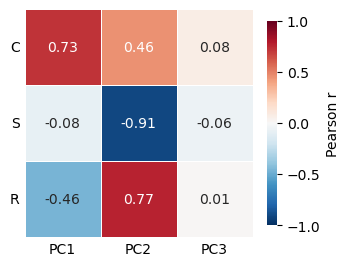

In [6]:
import seaborn as sns, matplotlib.pyplot as plt

CSR_COLS = ["C", "S", "R"]  
PC_COLS = ["PC1", "PC2", "PC3"]
sub = corr_matrix.loc[CSR_COLS, PC_COLS]   # rows C, S, R; columns PC1–3

fig, ax = plt.subplots(figsize=(3.6, 3))
sns.heatmap(sub, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Pearson r", "shrink": 0.8}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", length=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()

plt.savefig("../../Results/Figures/CSR_PCA_maps_correlation.pdf", format="pdf", bbox_inches="tight")

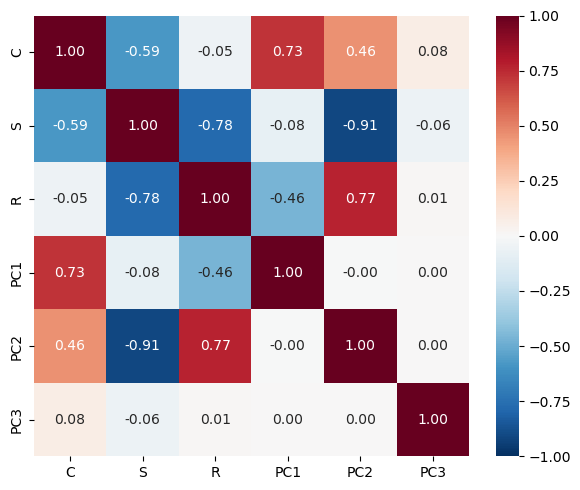

In [13]:
import seaborn as sns, matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, ax=ax)
#ax.set_title("Pearson r between spatial maps")
plt.tight_layout()

#save as pdf
plt.savefig("../../Results/Figures/CSR_PCA_maps_correlation.pdf", format="pdf", bbox_inches="tight")

In [9]:
pearson  = df[targets].corr(method="pearson")
spearman = df[targets].corr(method="spearman")

# difference matrix — large values flag non-linearity
diff = (spearman - pearson).abs()
print(diff.round(2))

        C     S     R   PC1   PC2   PC3
C    0.00  0.00  0.03  0.01  0.02  0.03
S    0.00  0.00  0.05  0.00  0.02  0.03
R    0.03  0.05  0.00  0.02  0.01  0.05
PC1  0.01  0.00  0.02  0.00  0.02  0.05
PC2  0.02  0.02  0.01  0.02  0.00  0.06
PC3  0.03  0.03  0.05  0.05  0.06  0.00


In [ ]:
import pandas as pd
import numpy as np
from pysr import PySRRegressor

# ── 1. Load your data ──────────────────────────────────────────────────────────
# Adjust paths to wherever your CSVs live
trait_df = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree_group_with_CSR.csv")

# Columns needed: PC1, PC2, PC3, and your CSR score columns
# Adjust column names to match yours
PC_COLS  = ["PC1", "PC2", "PC3"]
CSR_COLS = ["C", "S", "R"]          # or whatever your column names are

df = trait_df[PC_COLS + CSR_COLS].dropna()

X = df[PC_COLS].to_numpy()          # shape (n_cells, 3)

# ── 2. Optional: CLR-transform CSR scores so they behave like real numbers ─────
# CSR scores are compositional (C+S+R = 100 or 1), so raw regression can
# violate the constraint. Isometric log-ratio (ILR) or centred log-ratio (CLR)
# gives unconstrained targets. Simplest option: just fit C and S, derive R = 1 - C - S.
# Here we fit all three independently for explorability, then you can enforce the constraint.

from scipy.special import logit

def clr(x, eps=1e-3):
    """Centred log-ratio transform. x rows should sum to 1."""
    x = np.clip(x, eps, 1 - eps)
    log_x = np.log(x)
    return log_x - log_x.mean(axis=1, keepdims=True)

# Normalise to proportions (0–1) if your CSR scores are percentages
csr = df[CSR_COLS].to_numpy()
if csr.max() > 1.5:
    csr = csr / 100.0
csr_clr = clr(csr)   # shape (n_cells, 3), zero-sum per row


In [14]:
# ── 3. Fit one symbolic regression per CSR component ───────────────────────────
# (or use the CLR-transformed targets for unconstrained regression)
def fit_sr(y, name, complexity=20, iterations=40, reproducible=False):
    model = PySRRegressor(
        niterations=iterations,
        maxsize=complexity,
        binary_operators=["+", "-", "*", "/"],
        unary_operators=["square", "cube", "sqrt", "abs", "log"],
        populations=30,
        population_size=50,
        tournament_selection_n=10,
        parsimony=0.002,
        batching=False,                    # evaluates on mini-batches; much faster with many cells
        #batch_size=1000,
        output_directory="sr_outputs",    # equations saved to sr_outputs/<run_id>/
        run_id=f"csr_{name}",
        random_state=42,
        # identical results between runs need a serial search (slower)
        deterministic=reproducible,
        parallelism="serial" if reproducible else "multithreading",
        verbosity=1,
    )
    model.fit(X, y, variable_names=PC_COLS)
    print(f"\n=== {name} — Pareto front ===")
    print(model.equations_[["complexity", "loss", "equation"]])
    return model


In [ ]:


# Fit on the raw scores (simple approach: just C and S, recover R later)
model_C = fit_sr(csr[:, 0], "C")
model_S = fit_sr(csr[:, 1], "S")
# Optionally fit R too for comparison, or derive: R = 1 - C_pred - S_pred

# ── 4. Pick your formula and evaluate ─────────────────────────────────────────
# PySR returns a Pareto front. Inspect it:
print(model_C.equations_)     # DataFrame: complexity, loss, equation string, sympy_format

# Get predictions from the best (lowest-loss) equation:
C_pred = model_C.predict(X)
S_pred = model_S.predict(X)
R_pred = np.clip(1 - C_pred - S_pred, 0, 1)   # enforce constraint

# Quick evaluation
from sklearn.metrics import r2_score
for name, y_true, y_pred in [("C", csr[:,0], C_pred),
                               ("S", csr[:,1], S_pred),
                               ("R", csr[:,2], R_pred)]:
    print(f"R²({name}) = {r2_score(y_true, y_pred):.3f}")

# ── 5. Extract the symbolic formula ───────────────────────────────────────────
import sympy
print("C formula:", model_C.sympy())
print("S formula:", model_S.sympy())

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pysr/sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
Compiling Julia backend...
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pysr/sr.py:1873: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(
[ Info: Started!



Expressions evaluated per second: 1.200e+04
Progress: 419 / 1200 total iterations (34.917%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.114e-02  0.000e+00  y = 0.23622
5           5.261e-03  1.875e-01  y = (PC1 + 11.34) * 0.020815
6           5.260e-03  7.189e-05  y = abs(PC1 + 11.34) * 0.020815
7           2.925e-03  5.870e-01  y = ((PC1 + PC2) - -11.703) * 0.020185
8           2.903e-03  7.342e-03  y = abs((PC1 + (PC2 - -11.351)) * 0.020758)
10          2.764e-03  2.462e-02  y = square((((PC1 + PC2) * 0.01089) - -0.23882) * 1.9947)
13          2.756e-03  9.855e-04  y = sqrt(abs(abs(cube((-0.42304 - ((PC2 + PC1) * 0.02625))...
                                       * 0.88448))))
15          2.755e-03  1.585e-04  y = sqrt(sqrt(abs(cube(square(abs((((PC1 + PC2) * 0.020514...


[ Info: Final population:
[ Info: Results saved to:


───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.114e-02  0.000e+00  y = 0.23622
5           5.261e-03  1.875e-01  y = (PC1 + 11.34) * 0.020815
6           5.260e-03  7.189e-05  y = abs(PC1 + 11.34) * 0.020815
7           2.925e-03  5.870e-01  y = ((PC1 + PC2) - -11.703) * 0.020185
8           2.764e-03  5.639e-02  y = square(PC2 + (PC1 - -21.896)) * 0.00047443
10          2.755e-03  1.750e-03  y = cube(sqrt(abs(-0.37444 - ((PC2 + PC1) * 0.022932))))
12          2.753e-03  3.306e-04  y = sqrt(abs(cube(-0.3752 - ((PC2 + (PC1 * 1.0164)) * 0.02...
                                      2756))))
14          2.713e-03  7.218e-03  y = sqrt(cube(abs((((PC3 * 0.24107) + (PC1 + PC2)) * 0.022...
                                      932) - -0.37444)))
16          2.711e-03  4.018e-04  y = sqrt(cube(abs((-0.33572 - ((PC2 + (PC1 + (PC3 * 0.1902...
                                      6))) * 

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pysr/sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pysr/sr.py:1873: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(


  - sr_outputs/csr_C/hall_of_fame.csv

Expressions evaluated per second: 2.390e+04
Progress: 694 / 1200 total iterations (57.833%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.825e-02  0.000e+00  y = 0.51443
5           4.846e-03  4.407e-01  y = (PC2 * -0.059997) + 0.51483
6           4.817e-03  6.101e-03  y = abs((PC2 * -0.060241) + 0.51425)
9           4.673e-03  1.011e-02  y = ((PC2 - (-0.058744 * PC1)) * -0.058744) + 0.51371
10          4.648e-03  5.479e-03  y = abs(0.51256 + ((PC2 - (-0.05889 * PC1)) * -0.05889))
11          4.403e-03  5.396e-02  y = ((-0.058254 - (PC1 * -0.0017248)) * (PC2 - 1.1864)) + ...
                                      0.44511
12          4.376e-03  6.299e-03  y = abs(((PC2 - 1.1864) * (-0.058254 - (PC1 * -0.0017248))...
                         

[ Info: Started!
[ Info: Final population:


───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.825e-02  0.000e+00  y = 0.51443
5           4.846e-03  4.407e-01  y = (PC2 * -0.059997) + 0.51483
6           4.817e-03  6.102e-03  y = abs((PC2 * -0.060263) + 0.51443)
8           4.669e-03  1.556e-02  y = 0.98427 - abs((PC2 * 0.062758) + 0.4704)
9           4.610e-03  1.281e-02  y = ((-0.058254 - (PC1 * -0.0012989)) * PC2) + 0.50581
10          4.469e-03  3.106e-02  y = ((PC2 * -0.061191) + 0.52853) - square(PC1 * 0.031767)
11          4.403e-03  1.478e-02  y = ((-0.058254 - (PC1 * -0.0017248)) * (PC2 - 1.1864)) + ...
                                      0.44511
12          4.011e-03  9.323e-02  y = ((PC2 * -0.06123) - (square(PC2 - PC1) * 0.00086473)) ...
                                      + 0.53025
13          3.931e-03  2.033e-02  y = abs((square(PC2 - PC1) * 0.0010185) - ((PC2 * -0.06207...
                               

[ Info: Results saved to:


R²(C) = 0.737
R²(S) = 0.828
R²(R) = 0.814
C formula: (PC1 + PC2 - 1*(-11.703075))*0.020184694
S formula: 0.5148275 + PC2*(-0.059997164)
  - sr_outputs/csr_S/hall_of_fame.csv


In [16]:
def fit_sr(y, name, X_train, complexity=20, iterations=40, reproducible=False):
    model = PySRRegressor(
        niterations=iterations,
        maxsize=complexity,
        binary_operators=["+", "-", "*", "/"],
        unary_operators=["square", "cube", "sqrt", "abs", "log"],
        populations=30,
        population_size=50,
        tournament_selection_n=10,
        parsimony=0.002,
        batching=False,                   # ~10k cells: score on all training cells
        output_directory="sr_outputs",    # equations saved to sr_outputs/<run_id>/
        run_id=f"csr_{name}",
        random_state=42,
        # identical results between runs need a serial search (slower)
        deterministic=reproducible,
        parallelism="serial" if reproducible else "multithreading",
        verbosity=1,
    )
    model.fit(X_train, y, variable_names=PC_COLS)
    return model

In [17]:
from sklearn.metrics import r2_score

# --- spatial hold-out using the folds from notebook 02 ------------------------
folds = pd.read_csv("~/Func_Neo_Phytes/Results/trait_env/spatial_folds.csv")  # from xgboot SHAP analysis
# keep the H3 id when building df; "h3_index" is my guess at your column name, so adjust it
df = (trait_df[trait_df["group"] == "all"]
      .rename(columns={"h3_res3": "h3_index"})
      [["h3_index"] + PC_COLS + CSR_COLS].dropna()
      .merge(folds[["h3_index", "fold"]], on="h3_index"))
assert df["h3_index"].is_unique

rng = np.random.default_rng(42)
fold_ids = df["fold"].unique()
test_folds = rng.choice(fold_ids, size=round(0.2 * len(fold_ids)), replace=False)
is_test = df["fold"].isin(test_folds).to_numpy()
print(f"train {np.sum(~is_test)} cells, test {np.sum(is_test)} cells ({len(test_folds)} of {len(fold_ids)} folds)")

X = df[PC_COLS].to_numpy()
csr = df[CSR_COLS].to_numpy()
if csr.max() > 1.5:
    csr = csr / 100.0

def fit_and_score(j, name):
    model = fit_sr(csr[~is_test, j], name, X_train=X[~is_test])
    # score every equation on the Pareto front on the held-out folds
    eq = model.equations_[["complexity", "equation"]].copy()
    eq["R2_train"] = [r2_score(csr[~is_test, j], model.predict(X[~is_test], index=i)) for i in eq.index]
    eq["R2_test"]  = [r2_score(csr[is_test, j],  model.predict(X[is_test],  index=i)) for i in eq.index]
    print(f"\n=== {name} ===")
    print(eq.to_string(index=False))
    return model, eq

model_C, eq_C = fit_and_score(0, "C")
model_S, eq_S = fit_and_score(1, "S")

train 8002 cells, test 1609 cells (8 of 41 folds)


/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pysr/sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pysr/sr.py:1873: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(
[ Info: Started!



Expressions evaluated per second: 8.780e+04
Progress: 246 / 1200 total iterations (20.500%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           9.492e-03  0.000e+00  y = 0.23103
5           4.598e-03  1.812e-01  y = (PC1 * 0.020308) - -0.23879
6           4.598e-03  3.958e-05  y = abs((PC1 * -0.020325) - 0.23878)
7           2.652e-03  5.501e-01  y = ((PC2 + PC1) * 0.01951) - -0.23264
8           2.522e-03  5.051e-02  y = square(((PC2 + PC1) * -0.021389) - 0.474)
9           2.522e-03  7.153e-07  y = abs(square(((PC2 + PC1) * -0.021394) - 0.47401))
11          2.522e-03  1.073e-06  y = square(abs((((PC1 + PC2) * -0.083579) - 1.8501) * 0.25...
                                      618))
14          2.520e-03  1.798e-04  y = square((0.4893 - ((0.88491 - PC1) * 0.021582)) + ((PC2...
    

[ Info: Final population:
[ Info: Results saved to:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pysr/sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pysr/sr.py:1873: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(


  - sr_outputs/csr_C/hall_of_fame.csv

Expressions evaluated per second: 1.640e+05
Progress: 367 / 1200 total iterations (30.583%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.615e-02  0.000e+00  y = 0.49818
5           4.419e-03  4.445e-01  y = (PC2 * -0.060625) - -0.51634
6           4.386e-03  7.455e-03  y = abs((PC2 * -0.060871) - -0.51627)
8           4.384e-03  1.705e-04  y = abs((PC2 * -0.060918) - -0.53381) + -0.017561
9           4.309e-03  1.748e-02  y = (-0.060573 * (PC2 - (-0.052843 * PC1))) - -0.51174
10          4.160e-03  3.516e-02  y = ((PC2 * -0.062067) - -0.52704) - square(PC1 * 0.02921)
14          4.050e-03  6.697e-03  y = ((PC2 * -0.061808) - -0.52743) - square(((PC1 * 0.0106...
                                      04) + 0.020688) * 2.5928)
15          4.

[ Info: Started!



Expressions evaluated per second: 1.570e+05
Progress: 754 / 1200 total iterations (62.833%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.615e-02  0.000e+00  y = 0.49818
5           4.419e-03  4.445e-01  y = (PC2 * -0.060625) - -0.51634
6           4.386e-03  7.455e-03  y = abs((PC2 * -0.060871) - -0.51627)
8           4.384e-03  1.705e-04  y = abs((PC2 * -0.060918) - -0.53381) + -0.017561
9           4.297e-03  2.010e-02  y = (PC2 * -0.060573) - ((PC1 * 0.003201) - 0.5151)
10          4.160e-03  3.254e-02  y = ((PC2 * -0.061928) - -0.52704) - square(PC1 * 0.029128...
                                      )
11          4.123e-03  8.875e-03  y = abs(((PC2 * -0.062217) - -0.52698) - square(PC1 * 0.02...
                                      9491))
12          3.827e-03  7.435e-0

[ Info: Final population:
[ Info: Results saved to:



=== S ===
 complexity                                                                                           equation      R2_train   R2_test
          1                                                                                         0.49817857 -3.738740e-10 -0.125229
          5                                                                 (PC2 * -0.060624514) - -0.51634043  8.309953e-01  0.819747
          6                                                              abs((PC2 * -0.06087133) - -0.5162662)  8.322505e-01  0.820910
          8                                             abs((PC2 * -0.060918096) - -0.53381264) + -0.017561218  8.323077e-01  0.820756
          9                                            abs(0.9806374 - abs((PC2 * 0.062798545) - -0.46241564))  8.368859e-01  0.839595
         10                                ((PC2 * -0.061965577) - -0.52713346) - (square(PC1) * 0.0008647204)  8.409113e-01  0.842045
         11                                a